# Introduction to Machine Learning – Lab 2
## Model Diagnostics: Trees, Feature Importance, Metrics, Curves and Thresholds

### Objective
This notebook looks inside the baseline model of notebook 02 (cleaned data without the 5 extreme houses and the 7 nearly constant features, one-hot encoding of the nominal features, default XGBoost hyperparameters) and evaluates it in more detail:
1. **First and best tree:** the first tree of the ensemble vs. the tree of the best boosting round (early stopping).
2. **Feature importance:** **gain** (average loss reduction per split) vs. **split / weight** (number of splits on a feature).
3. **Classification metrics and confusion matrix:** precision, recall, F1 and accuracy, per class and overall.
4. **ROC and precision-recall curves:** one-vs-rest for each of the six price classes.
5. **Thresholds:** per-class thresholds on the precision-recall curves that give the best macro-F1.

Sections 3–5 use the out-of-fold predictions of the 5-fold stratified cross-validation of notebook 02 (same folds), so every house is predicted by a model that did not see it during training. Each section ends with the interpretation of its results.

In [1]:
import sys
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    auc,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from xgboost import XGBClassifier, plot_tree

from evaluation import make_splits
from preprocessing import CLASS_NAMES, build_pipeline, make_preprocessor, prepare_data

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

# Same data and model as notebook 02
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
print(f"Dataset dimensions: X = {X.shape}, y = {y.shape}")

pipe = build_pipeline(strategy="onehot", min_frequency=5, enable_categorical=False, tree_method="hist")

# The 5 folds of "CV k=5, stratified" (StratifiedKFold, shuffle=True, random_state=42), as in notebook 02
splits = [split for split in make_splits(y) if split["Setup"] == "CV k=5, stratified"]

# Out-of-fold (OOF) probabilities: every house is predicted by the model of the fold it was not trained on
oof_proba = np.zeros((len(y), len(CLASS_NAMES)))
fold_rows = []
for split in splits:
    model = clone(pipe).fit(X.loc[split["train"]], y.loc[split["train"]])
    positions = y.index.get_indexer(split["test"])
    oof_proba[positions] = model.predict_proba(X.loc[split["test"]])
    fold_pred = oof_proba[positions].argmax(axis=1)
    fold_rows.append({
        "Accuracy": accuracy_score(y.iloc[positions], fold_pred),
        "Macro-F1": f1_score(y.iloc[positions], fold_pred, average="macro"),
    })
oof_pred = oof_proba.argmax(axis=1)

# Population standard deviation over the folds, as printed in notebook 02
fold_scores = pd.DataFrame(fold_rows)
print("5-fold stratified CV, mean ± std over the folds:")
for metric in fold_scores:
    print(f"  {metric}: {fold_scores[metric].mean():.4f} ± {fold_scores[metric].std(ddof=0):.4f}")

Dataset dimensions: X = (2925, 72), y = (2925,)


5-fold stratified CV, mean ± std over the folds:
  Accuracy: 0.7641 ± 0.0192
  Macro-F1: 0.7494 ± 0.0211


Same data, model and folds as in notebook 02, and the same scores: accuracy 0.7641 ± 0.0192 and macro-F1 0.7494 ± 0.0211, as for `5-Fold CV (StratifiedKFold)` there. These are means over the five folds. Sections 3–5 compute the metrics once over all 2,925 pooled out-of-fold predictions, so the pooled macro-F1 there (0.7518) differs slightly from the mean of the five fold scores.

### 1. First tree vs. best tree

For six classes, XGBoost builds six trees per boosting round, one per price class. Each tree adds a score to its class, and the softmax over the six summed scores gives the class probabilities. The index of a tree is therefore `round × 6 + class`.

* **First tree:** round 0, class 0 (`< 100k`), index 0. It is fitted to the gradient of the log-loss of the starting prediction, so it captures the strongest patterns in the data.
* **Best tree:** the class-0 tree of the best round. With early stopping, boosting stops once the log-loss on a 20% stratified validation split has not improved for 20 rounds. The best round is the one with the lowest validation log-loss, and the model predicts with the trees up to this round, so its trees are the last ones that still improve the model on new houses.

The baseline grows trees up to depth 6 (up to 64 leaves), which is too large to read in a plot. The trees are therefore drawn from a model with `max_depth=3`, trained with its own early stopping on the same split. The depth-6 model with early stopping is used for the feature importance in Section 2. Both use `learning_rate=0.1` instead of the default 0.3, so that each round changes the model less and the best round can be located more precisely.

max_depth=6: best round 105 (validation mlogloss 0.5825)
max_depth=3: best round 282 (validation mlogloss 0.5641)


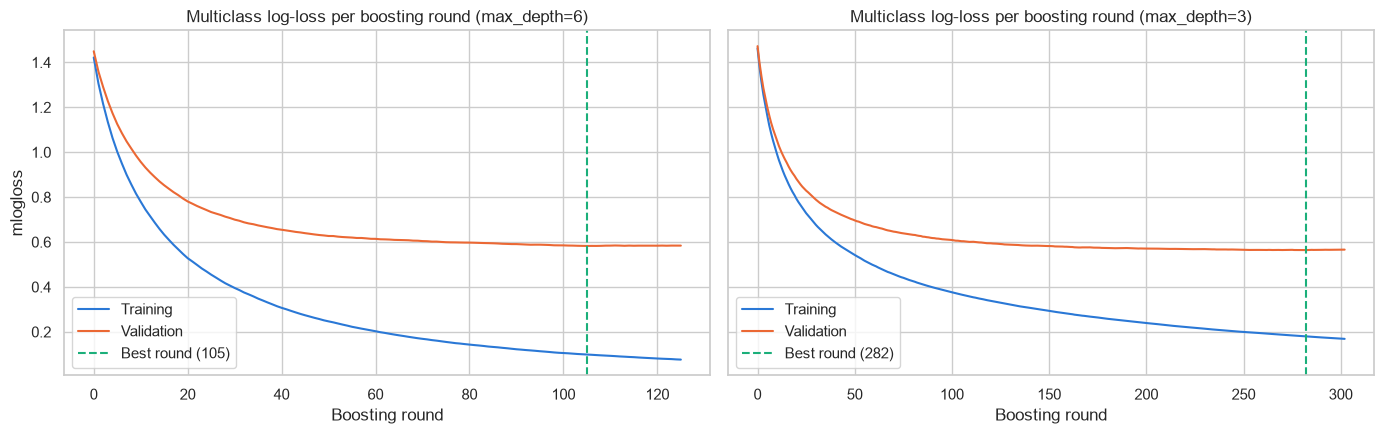

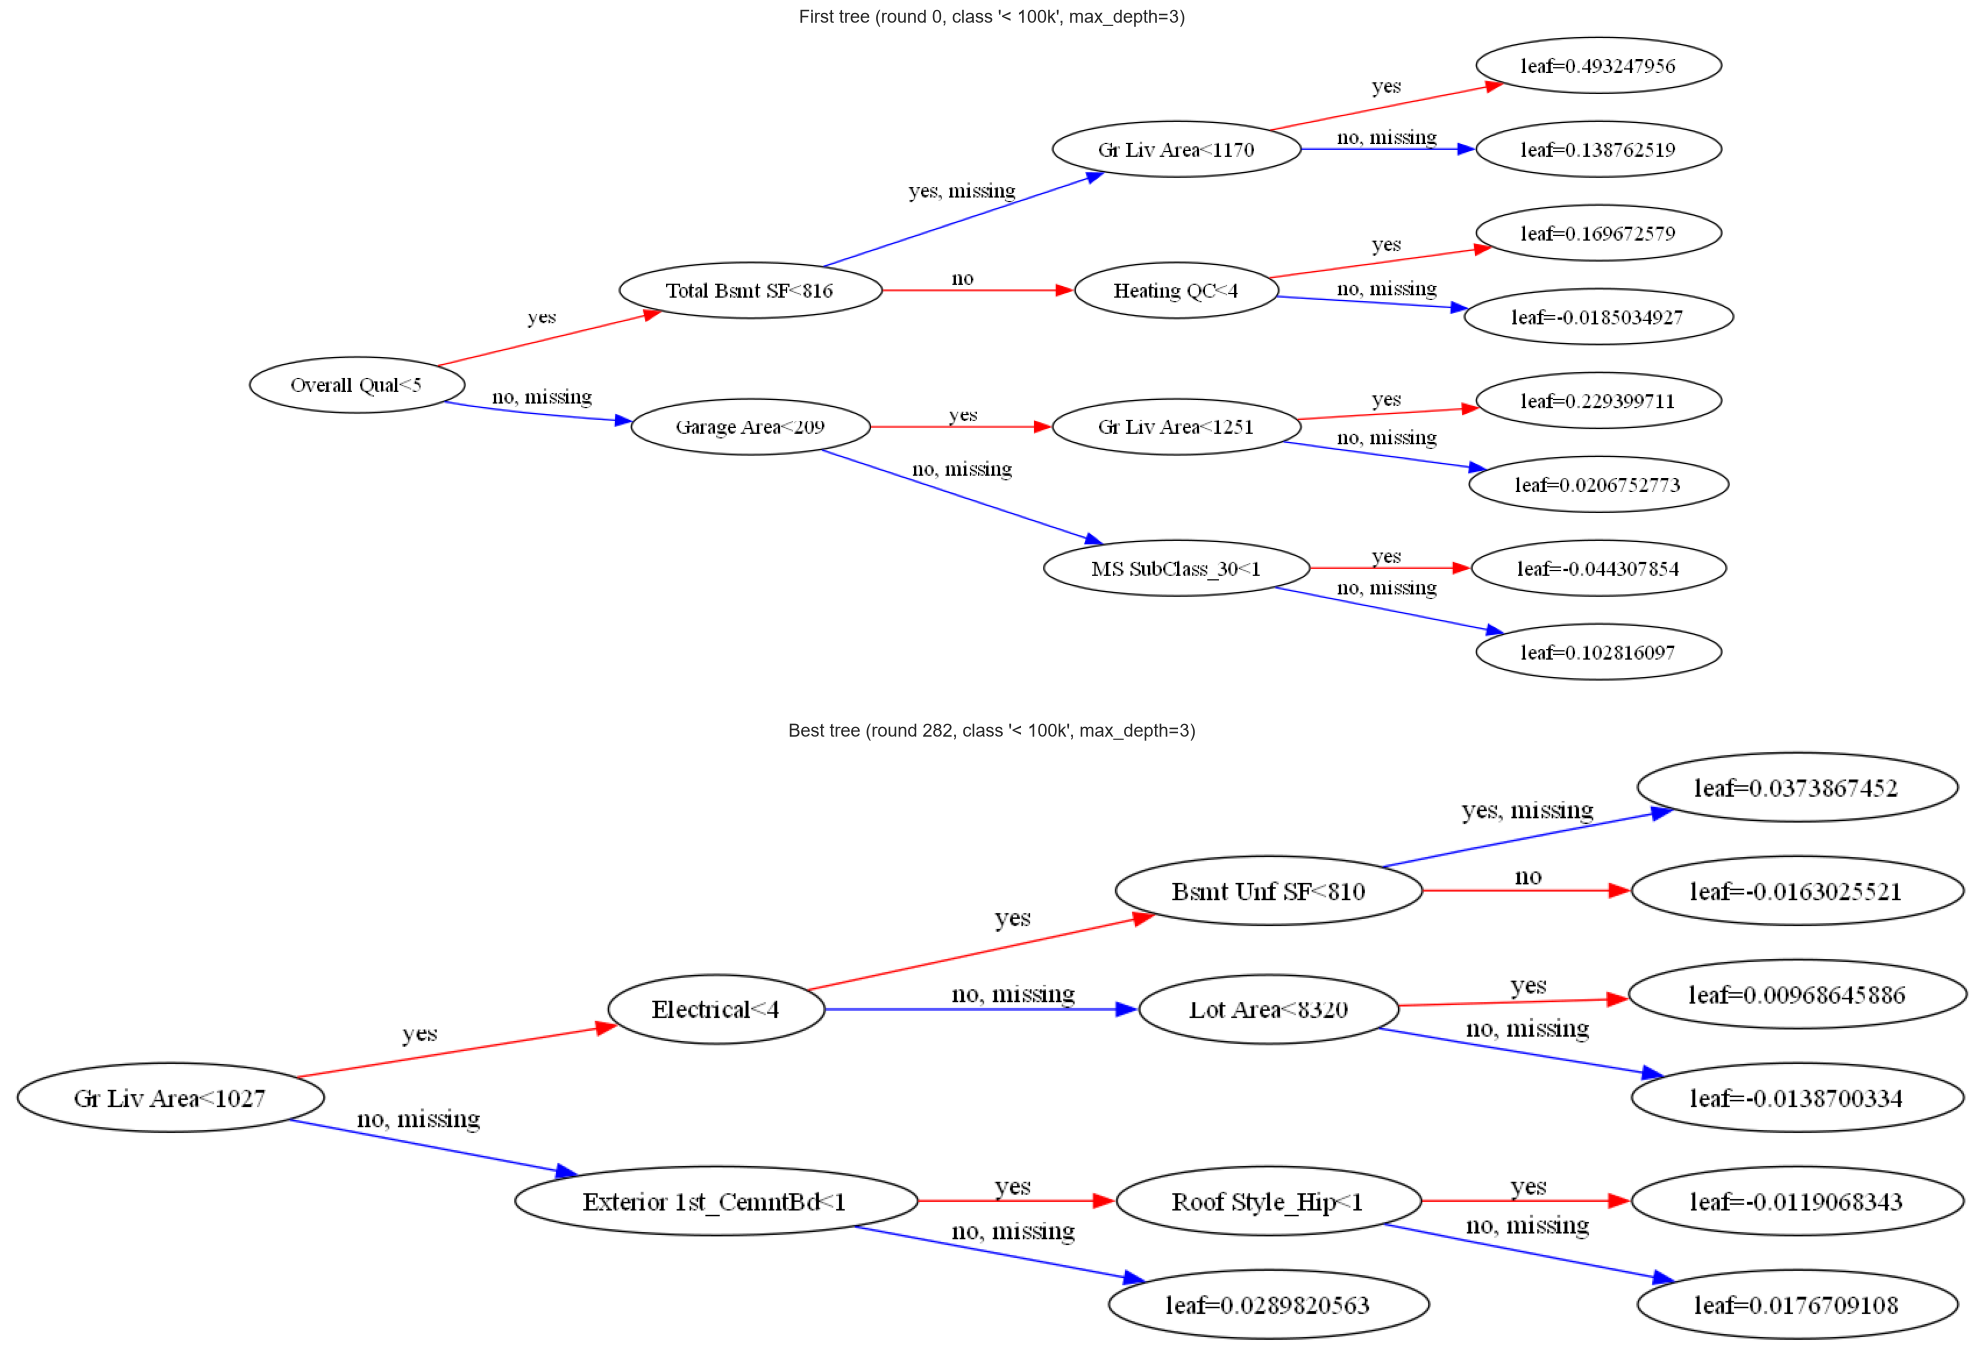

--- First tree (index 0: round 0, class '< 100k') ---
0:[Overall Qual<5] yes=1,no=2,missing=2,gain=305.576172,cover=347.471222
	1:[Total Bsmt SF<816] yes=3,no=4,missing=3,gain=77.6828918,cover=33.1137123
		3:[Gr Liv Area<1170] yes=7,no=8,missing=8,gain=41.5079041,cover=19.7494335
			7:leaf=0.493247956,cover=14.2552299
			8:leaf=0.138762519,cover=5.49420309
		4:[Heating QC<4] yes=9,no=10,missing=10,gain=12.7856426,cover=13.3642778
			9:leaf=0.169672579,cover=7.27610683
			10:leaf=-0.0185034927,cover=6.08817101
	2:[Garage Area<209] yes=5,no=6,missing=6,gain=56.2675095,cover=314.357513
		5:[Gr Liv Area<1251] yes=11,no=12,missing=12,gain=16.442215,cover=15.4431658
			11:leaf=0.229399711,cover=9.05801105
			12:leaf=0.0206752773,cover=6.3851552
		6:[MS SubClass_30<1] yes=13,no=14,missing=14,gain=16.649395,cover=298.914368
			13:leaf=-0.044307854,cover=291.935242
			14:leaf=0.102816097,cover=6.97912312

--- Best tree (index 1692: round 282, class '< 100k') ---
0:[Gr Liv Area<1027] yes=1,no=2,

In [2]:
# 80/20 stratified split: the 20% validation houses decide when boosting stops
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
prep = make_preprocessor(strategy="onehot", min_frequency=5)
X_train_enc = prep.fit_transform(X_train, y_train)
X_val_enc = prep.transform(X_val)
num_classes = len(CLASS_NAMES)


def fit_with_early_stopping(max_depth):
    """XGBoost that stops once the validation log-loss has not improved for 20 rounds."""
    model = XGBClassifier(
        n_estimators=1000,
        learning_rate=0.1,
        max_depth=max_depth,
        eval_metric="mlogloss",
        early_stopping_rounds=20,
        tree_method="hist",
        random_state=42,
    )
    model.fit(X_train_enc, y_train, eval_set=[(X_train_enc, y_train), (X_val_enc, y_val)], verbose=False)
    return model


# Depth 6 as in the baseline (feature importance, Section 2) and depth 3 (trees small enough to read)
models = {"max_depth=6": fit_with_early_stopping(max_depth=6), "max_depth=3": fit_with_early_stopping(max_depth=3)}
xgb_full, xgb_vis = models["max_depth=6"], models["max_depth=3"]
for name, model in models.items():
    print(f"{name}: best round {model.best_iteration} (validation mlogloss {model.best_score:.4f})")

# Learning curves: the best round is where the validation log-loss is lowest
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    curves = model.evals_result()
    ax.plot(curves["validation_0"]["mlogloss"], label="Training", color="#2a78d6")
    ax.plot(curves["validation_1"]["mlogloss"], label="Validation", color="#eb6834")
    ax.axvline(model.best_iteration, color="#1baf7a", linestyle="--", label=f"Best round ({model.best_iteration})")
    ax.set_title(f"Multiclass log-loss per boosting round ({name})", fontsize=12)
    ax.set_xlabel("Boosting round")
    ax.legend()
axes[0].set_ylabel("mlogloss")
plt.tight_layout()
plt.show()

# Class 0 ("< 100k") in round 0 and in the best round of the depth-3 model
best_round = xgb_vis.best_iteration
first_tree_idx = 0
best_tree_idx = best_round * num_classes

try:
    fig, axes = plt.subplots(2, 1, figsize=(20, 14))
    plot_tree(xgb_vis, tree_idx=first_tree_idx, rankdir="LR", ax=axes[0])
    axes[0].set_title(f"First tree (round 0, class '{CLASS_NAMES[0]}', max_depth=3)", fontsize=13)
    plot_tree(xgb_vis, tree_idx=best_tree_idx, rankdir="LR", ax=axes[1])
    axes[1].set_title(f"Best tree (round {best_round}, class '{CLASS_NAMES[0]}', max_depth=3)", fontsize=13)
    plt.tight_layout()
    plt.show()
except Exception as e:
    # plot_tree needs the Graphviz program (dot) on the PATH, not only the Python package
    plt.close(fig)
    print(f"Could not draw the trees ({e}); the split rules are printed below.\n")

# Split rules with gain (loss reduction) and cover (sum of hessians) of every node
dumps = xgb_vis.get_booster().get_dump(with_stats=True)
print(f"--- First tree (index {first_tree_idx}: round 0, class '{CLASS_NAMES[0]}') ---")
print(dumps[first_tree_idx])
print(f"--- Best tree (index {best_tree_idx}: round {best_round}, class '{CLASS_NAMES[0]}') ---")
print(dumps[best_tree_idx])

#### Interpretation of the trees

**Learning curves.**
* The training log-loss falls with every round, while the validation log-loss levels off. The depth-6 model reaches its lowest validation log-loss (0.5825) in round 105, the depth-3 model (0.5641) in round 282. After that, new trees only fit the training houses better: the training log-loss ends below 0.2 in both curves, the validation log-loss stays above 0.56.
* The depth-3 model needs more than twice as many rounds, because each of its trees can only use three splits along a path. It ends with a lower validation log-loss and a smaller gap to its training log-loss than the depth-6 model. This matches the high variance found in notebook 02: smaller trees overfit less.

**First tree (round 0).**
* The root splits on `Overall Qual < 5` with a gain of 305.6, by far the largest in the tree (next: 77.7 for `Total Bsmt SF < 816`). For the class `< 100k`, overall quality is the strongest single signal.
* Below the root, the tree uses size features: `Total Bsmt SF`, `Gr Liv Area` and `Garage Area`. The largest leaf value (+0.493) goes to houses with quality below 5, a basement below 816 ft² and a living area below 1,170 ft², the small low-quality houses, whose score for `< 100k` rises the most.
* The largest branch, quality ≥ 5 and a garage of at least 209 ft² (cover 298.9 of 347.5), gets a negative value (−0.044) unless the house is a 1-story house built in 1945 or earlier (`MS SubClass_30`, +0.103).

**Best tree (round 282).**
* The splits are weak: the gains are 0.24–0.39 instead of up to 305.6, and the leaf values (−0.016 to +0.037) are more than ten times smaller than in the first tree (up to +0.493).
* The cover of the root drops from 347.5 to 69.5. Cover is the sum of the hessians, which for the softmax log-loss are proportional to $p(1-p)$ per house. Once the model is confident about a house ($p$ close to 0 or 1), the house hardly influences the later trees, and they work on the remaining hard houses near a class boundary.
* The root still splits on living area (`Gr Liv Area < 1027`), but below it the tree uses features the first tree did not need: `Electrical`, `Bsmt Unf SF`, `Lot Area` and the one-hot columns `Exterior 1st_CemntBd` and `Roof Style_Hip`, two of the leaves with a cover of only 1.1 and 1.9. Such small corrections on few houses can just as well fit noise. Early stopping ends training at the point where they stop improving the validation log-loss.

### 2. Feature importance: gain vs. split (weight)

XGBoost measures the importance of a feature in several ways (`Booster.get_score`):
1. **Gain (`gain`):** the average reduction of the training loss over all splits on the feature.
2. **Split / weight (`weight`):** the number of splits on the feature, over all trees.
3. **Total gain (`total_gain`):** gain × weight, the summed loss reduction of all splits on the feature. It is shown as a third column in the table, because it combines how often and how strongly a feature is used.

The importance is taken from the depth-6 model of Section 1, using only the trees up to its best round, which are the trees used for predictions.

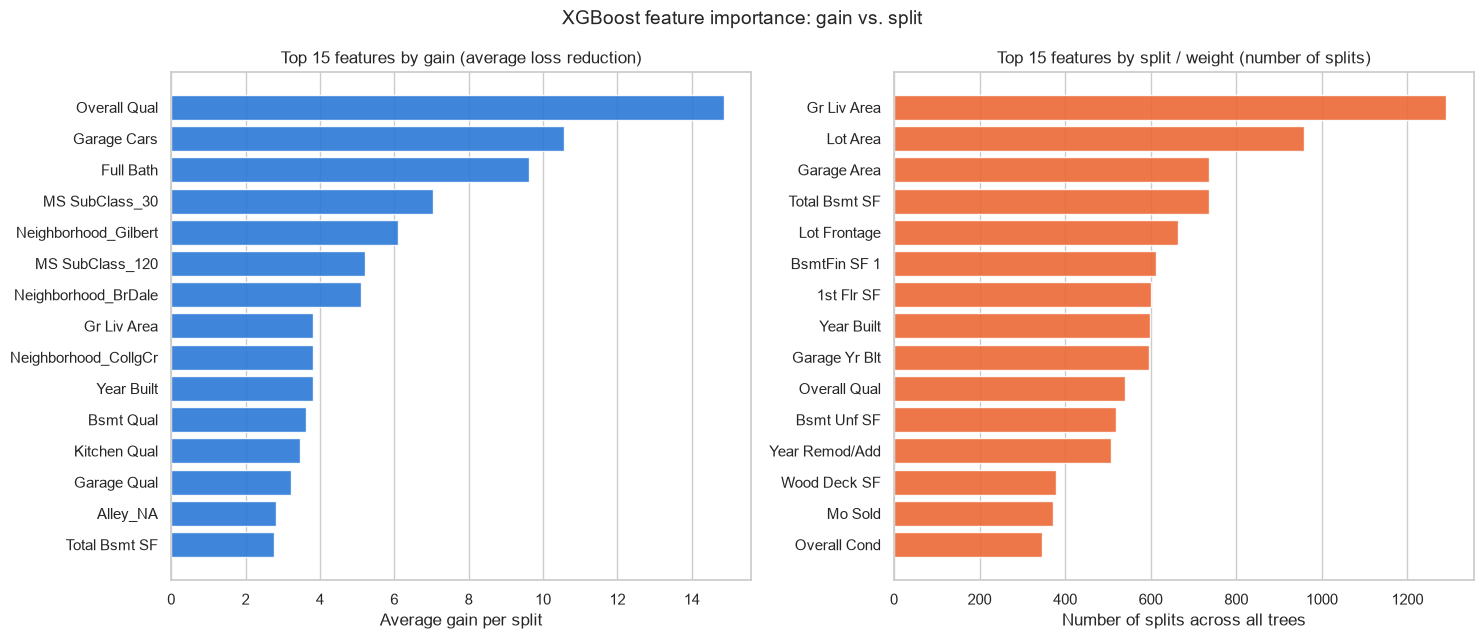

164 of 200 encoded features are used in at least one split.

Top 15 by gain:


,Gain,Split (Weight),Total Gain,Gain Rank,Split Rank,Total Rank
Overall Qual,14.85,540.0,8021.60,1,10,1
Garage Cars,10.55,54.0,569.70,2,45,13
Full Bath,9.63,75.0,722.36,3,37,11
MS SubClass_30,7.03,13.0,91.42,4,103,42
Neighborhood_Gilbert,6.11,9.0,54.99,5,121,54
MS SubClass_120,5.23,6.0,31.35,6,135,74
Neighborhood_BrDale,5.09,15.0,76.42,7,97,44
Gr Liv Area,3.81,1291.0,4913.64,8,1,2
Neighborhood_CollgCr,3.80,64.0,243.37,9,42,24
Year Built,3.80,599.0,2276.45,10,8,3


Top 10 by total gain:


,Gain,Split (Weight),Total Gain,Gain Rank,Split Rank,Total Rank
Overall Qual,14.85,540.0,8021.60,1,10,1
Gr Liv Area,3.81,1291.0,4913.64,8,1,2
Year Built,3.80,599.0,2276.45,10,8,3
Total Bsmt SF,2.76,736.0,2031.25,15,3,4
Garage Area,2.03,736.0,1497.00,23,3,5
Lot Area,1.37,959.0,1315.66,51,2,6
1st Flr SF,1.80,601.0,1080.82,31,7,7
Garage Yr Blt,1.76,597.0,1050.41,33,9,8
BsmtFin SF 1,1.64,613.0,1005.74,37,6,9
Year Remod/Add,1.71,508.0,870.96,34,12,10


In [3]:
# Only the rounds up to the best round; the 20 rounds after it are not used for predictions
booster = xgb_full.get_booster()[: xgb_full.best_iteration + 1]

df_imp = pd.DataFrame({
    "Gain": pd.Series(booster.get_score(importance_type="gain")),
    "Split (Weight)": pd.Series(booster.get_score(importance_type="weight")),
    "Total Gain": pd.Series(booster.get_score(importance_type="total_gain")),
}).fillna(0)

top_gain = df_imp["Gain"].sort_values(ascending=False).head(15).iloc[::-1]
top_weight = df_imp["Split (Weight)"].sort_values(ascending=False).head(15).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

axes[0].barh(top_gain.index, top_gain.values, color="#2a78d6", alpha=0.9)
axes[0].set_title("Top 15 features by gain (average loss reduction)", fontsize=12)
axes[0].set_xlabel("Average gain per split")
axes[0].grid(axis="y", visible=False)

axes[1].barh(top_weight.index, top_weight.values, color="#eb6834", alpha=0.9)
axes[1].set_title("Top 15 features by split / weight (number of splits)", fontsize=12)
axes[1].set_xlabel("Number of splits across all trees")
axes[1].grid(axis="y", visible=False)

fig.suptitle("XGBoost feature importance: gain vs. split", fontsize=14)
plt.tight_layout()
plt.show()

for col in ["Gain", "Split (Weight)", "Total Gain"]:
    df_imp[f"{col.split()[0]} Rank"] = df_imp[col].rank(ascending=False, method="min").astype(int)
print(f"{len(df_imp)} of {X_train_enc.shape[1]} encoded features are used in at least one split.")
print("\nTop 15 by gain:")
display(df_imp.sort_values("Gain", ascending=False).head(15).round(2))
print("Top 10 by total gain:")
display(df_imp.sort_values("Total Gain", ascending=False).head(10).round(2))

#### Interpretation of the feature importance
* **The two measures rank the features very differently.** By gain, `Overall Qual` leads (14.85 per split), followed by `Garage Cars` (10.55), `Full Bath` (9.63) and several one-hot columns: `MS SubClass_30` (7.03), `Neighborhood_Gilbert` (6.11), `MS SubClass_120` (5.23). By split count, continuous size and year features lead: `Gr Liv Area` (1,291 splits), `Lot Area` (959), `Garage Area` and `Total Bsmt SF` (736 each).
* **Why rarely used features get a high gain:** gain is an average per split. A one-hot column has only two values, and it is chosen only where it separates a clear group, such as `MS SubClass_30` (1-story houses built in 1945 or earlier), which raises the score of `< 100k` in the first tree. Its 13 splits are all strong ones, so its average stays high. A continuous feature like `Lot Area` has hundreds of possible thresholds and is reused deep in the trees for small corrections. Its many small gains pull the average down: 1.37 per split, gain rank 51, but split rank 2.
* **Total gain combines both:** `Overall Qual` is first (8,022), followed by `Gr Liv Area` (4,914), `Year Built` (2,276), `Total Bsmt SF` (2,031) and `Garage Area` (1,497). The top 10 by total gain contain only quality, size and year features. None of the high-gain one-hot columns is among them (`MS SubClass_30` has total-gain rank 42). The model therefore mainly prices a house by its quality, size and age; the one-hot columns correct single groups of houses.
* **Near-duplicate features share their importance.** Several pairs that measure almost the same thing are both used often: `Year Built` (599 splits) and `Garage Yr Blt` (597), `Total Bsmt SF` (736) and `1st Flr SF` (601). `Garage Cars` takes few but strong splits on garage size (gain 10.55, 54 splits), `Garage Area` the many small ones (2.03, 736 splits). Each feature of such a pair looks less important than the information it carries. Notebook 04 tests dropping these features (variant *Without redundant*) and adding summed size features (*Size totals*), since here the trees need many splits on separate area columns to combine them.
* 164 of the 200 encoded columns are used in at least one split. The other 36 never give the best split.

### 3. Classification metrics and confusion matrix

The out-of-fold predictions of all 2,925 houses are compared with their true price classes:
- **Precision:** of the houses predicted as class $c$, the share that really belongs to $c$: $\frac{TP_c}{TP_c + FP_c}$
- **Recall:** of the houses of class $c$, the share the model finds: $\frac{TP_c}{TP_c + FN_c}$
- **F1:** the harmonic mean of both: $2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$
- **Accuracy:** the share of all houses that are classified correctly.
- **Macro-F1 / macro precision / macro recall:** the unweighted mean over the six classes, so the 62 houses ≥ \$400k count as much as the 1,036 houses of \$130k–\$180k. The weighted F1 instead weights each class by its number of houses.

--- Out-of-fold performance (5-fold stratified CV) ---


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,0.7641,0.7806,0.7298,0.7518,0.7627



--- Per-class performance ---


,Precision,Recall,F1-Score,Support (Houses)
< 100k,0.7716,0.6414,0.7005,237
100k–130k,0.6770,0.6424,0.6593,509
130k–180k,0.7743,0.8311,0.8017,1036
180k–250k,0.7688,0.7778,0.7733,684
250k–400k,0.8168,0.8086,0.8127,397
≥ 400k,0.8750,0.6774,0.7636,62


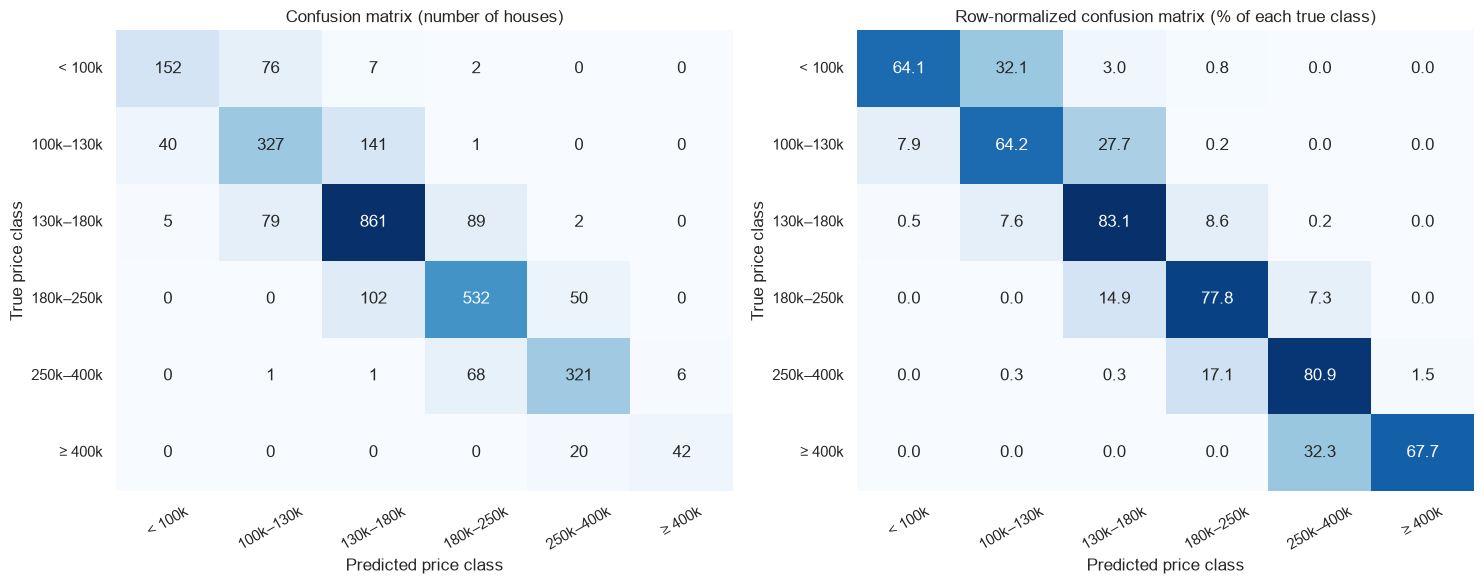

Misclassified houses: 690 / 2925 (23.6%)
Errors in an adjacent price class (|y_true - y_pred| == 1): 671 / 690 (97.2% of all errors)


In [4]:
# Overall summary metrics
overall_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y, oof_pred),
    "Macro Precision": precision_score(y, oof_pred, average="macro"),
    "Macro Recall": recall_score(y, oof_pred, average="macro"),
    "Macro F1": f1_score(y, oof_pred, average="macro"),
    "Weighted F1": f1_score(y, oof_pred, average="weighted"),
}]).round(4)

print("--- Out-of-fold performance (5-fold stratified CV) ---")
display(overall_metrics)

# Per-class detailed breakdown
report_dict = classification_report(y, oof_pred, target_names=CLASS_NAMES, output_dict=True)
df_report = pd.DataFrame(report_dict).T.iloc[:6][["precision", "recall", "f1-score", "support"]]
df_report["support"] = df_report["support"].astype(int)
df_report.columns = ["Precision", "Recall", "F1-Score", "Support (Houses)"]
print("\n--- Per-class performance ---")
display(df_report.round(4))

# Confusion matrices (raw counts and row-normalized = recall per true class)
cm_counts = confusion_matrix(y, oof_pred)
cm_norm = confusion_matrix(y, oof_pred, normalize="true") * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    cm_counts, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[0]
)
axes[0].set_title("Confusion matrix (number of houses)", fontsize=12)
axes[0].set_xlabel("Predicted price class")
axes[0].set_ylabel("True price class")
axes[0].tick_params(axis="x", rotation=30)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    cm_norm, annot=True, fmt=".1f", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[1]
)
axes[1].set_title("Row-normalized confusion matrix (% of each true class)", fontsize=12)
axes[1].set_xlabel("Predicted price class")
axes[1].set_ylabel("True price class")
axes[1].tick_params(axis="x", rotation=30)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

# How many errors are only one price class off
off_by_one = (np.abs(y - oof_pred) == 1).sum()
total_errors = (y != oof_pred).sum()
print(f"Misclassified houses: {total_errors} / {len(y)} ({total_errors/len(y):.1%})")
print(f"Errors in an adjacent price class (|y_true - y_pred| == 1): {off_by_one} / {total_errors} ({off_by_one/total_errors:.1%} of all errors)")

#### Interpretation of the metrics and the confusion matrix
* **Overall:** 76.4% of the houses are classified correctly (accuracy 0.7641), with a macro-F1 of 0.7518 and a weighted F1 of 0.7627. The macro precision (0.7806) is clearly higher than the macro recall (0.7298): when the model predicts a class it is usually right, but it misses part of the houses of some classes. The gap comes mainly from the two outer classes: `≥ 400k` has a precision of 0.875 but a recall of 0.677, and `< 100k` 0.772 vs. 0.641.
* **Best and worst classes:** `250k–400k` (0.813) and `130k–180k` (0.802) have the highest F1. `100k–130k` has the lowest (0.659), followed by `< 100k` (0.701). The `100k–130k` class is only \$30k wide and has neighbor classes on both sides: 40 of its houses are predicted as `< 100k` and 141 as `130k–180k`.
* **The outer classes lose houses to their larger neighbor:** 76 of the 237 houses `< 100k` (32.1%) are predicted as `100k–130k`, and 20 of the 62 houses `≥ 400k` (32.3%) as `250k–400k`. In the opposite direction, only 40 houses `100k–130k` (7.9%) are predicted as `< 100k`, and 6 houses `250k–400k` (1.5%) as `≥ 400k`. A likely reason is the imbalance: with few training houses in a class, the trees assign it high probabilities only for clear cases, so borderline houses go to the larger neighbor. Section 5 tries to shift this with class-specific thresholds.
* **Errors are almost always one class off:** 690 of 2,925 houses (23.6%) are misclassified, and 671 of these errors (97.2%) fall into an adjacent price class. Only 19 houses are off by two or three classes, none by more. The classes are intervals of one continuous price, and a house sold for \$128k is very similar to one sold for \$132k, so these errors are expected. Accuracy and macro-F1 count them the same as a confusion between `< 100k` and `≥ 400k`, which never happens.

### 4. ROC and precision-recall curves

For six classes, both curves are drawn one-vs-rest: class $c$ is the positive class, the other five classes together are the negative class, and the score of a house is its out-of-fold probability for class $c$.
* **ROC curve:** true positive rate (recall) against false positive rate, over all thresholds. The false positive rate divides by the number of negative houses, which is large for a small class.
* **Precision-recall curve:** precision against recall. It ignores the true negatives, so it shows how many false alarms come with every additional house of the class that is found.
* **Average precision (AP):** the area under the precision-recall curve, computed as the mean of the precisions at each threshold weighted by the increase in recall (`average_precision_score`). A random model reaches an AP equal to the share of the class in the data.
* **Stars on the precision-recall curves:** for each class, the threshold $\tau_c^*$ with the highest one-vs-rest F1 (used in Section 5):
  $$F1_c(\tau) = \frac{2 \cdot \text{Precision}_c(\tau) \cdot \text{Recall}_c(\tau)}{\text{Precision}_c(\tau) + \text{Recall}_c(\tau)}$$

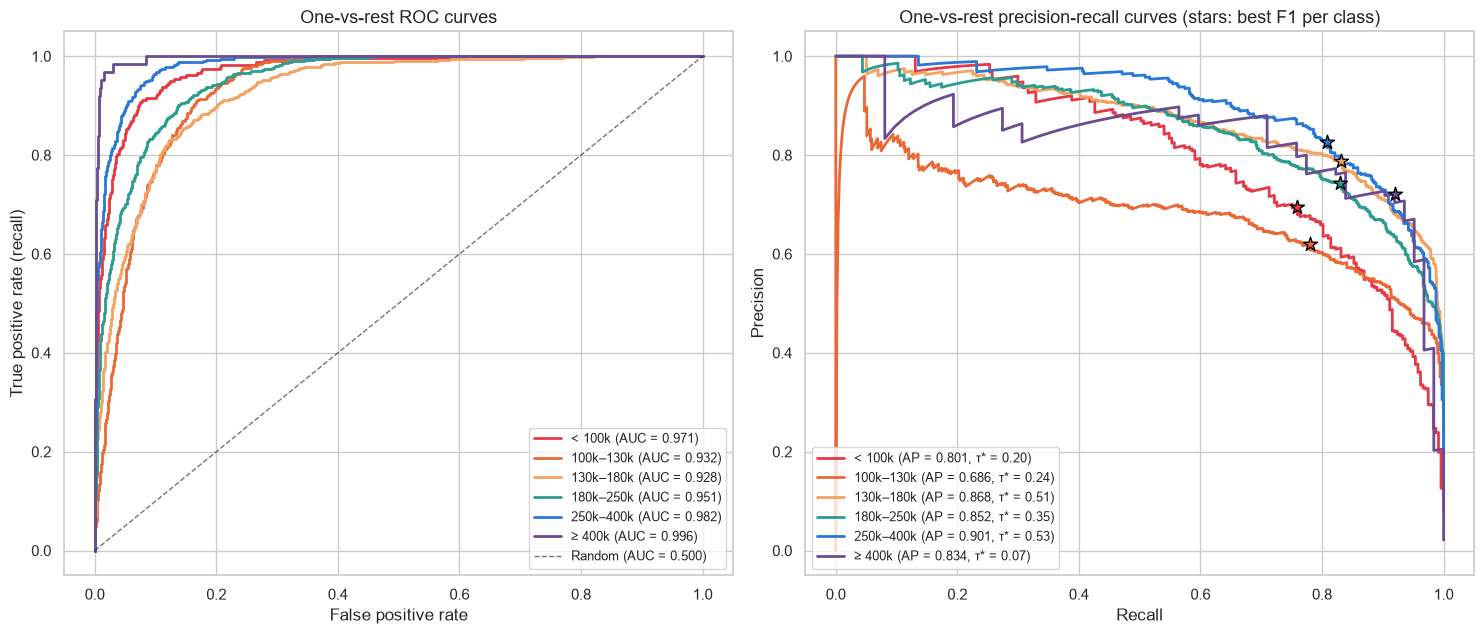

,Share (%),ROC AUC,Average Precision,τ*,Precision at τ*,Recall at τ*,OvR F1 at τ = 0.50,OvR F1 at τ*
Class,,,,,,,,
< 100k,8.10,0.9709,0.8009,0.1954,0.6950,0.7595,0.7021,0.7258
100k–130k,17.40,0.9324,0.6858,0.2432,0.6193,0.7800,0.6606,0.6904
130k–180k,35.42,0.9282,0.8684,0.5133,0.7877,0.8311,0.8073,0.8088
180k–250k,23.38,0.9511,0.8525,0.3532,0.7431,0.8289,0.7746,0.7837
250k–400k,13.57,0.9817,0.9007,0.5254,0.8273,0.8086,0.8147,0.8178
≥ 400k,2.12,0.9957,0.8340,0.0663,0.7215,0.9194,0.7636,0.8085


In [5]:
def best_f1_point(y_true_bin, score):
    """Point of the precision-recall curve with the highest F1: (threshold, precision, recall, F1)."""
    prec, rec, thresh = precision_recall_curve(y_true_bin, score)
    # The last point (precision 1, recall 0) has no threshold
    prec, rec = prec[:-1], rec[:-1]
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
    best = np.argmax(f1)
    return thresh[best], prec[best], rec[best], f1[best]


colors = ["#e63946", "#eb6834", "#f4a261", "#2a9d8f", "#2a78d6", "#6a4c93"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
curve_rows = []

for c in range(num_classes):
    y_true_bin = (y == c).to_numpy()
    y_score = oof_proba[:, c]

    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=colors[c], lw=2, label=f"{CLASS_NAMES[c]} (AUC = {roc_auc:.3f})")

    prec, rec, _ = precision_recall_curve(y_true_bin, y_score)
    ap = average_precision_score(y_true_bin, y_score)
    tau, best_p, best_r, best_f1 = best_f1_point(y_true_bin, y_score)
    axes[1].plot(rec, prec, color=colors[c], lw=2, label=f"{CLASS_NAMES[c]} (AP = {ap:.3f}, τ* = {tau:.2f})")
    axes[1].scatter(best_r, best_p, color=colors[c], edgecolors="black", s=110, zorder=5, marker="*")

    curve_rows.append({
        "Class": CLASS_NAMES[c],
        "Share (%)": round(y_true_bin.mean() * 100, 2),
        "ROC AUC": roc_auc,
        "Average Precision": ap,
        "τ*": tau,
        "Precision at τ*": best_p,
        "Recall at τ*": best_r,
        "OvR F1 at τ = 0.50": f1_score(y_true_bin, y_score >= 0.50),
        "OvR F1 at τ*": best_f1,
    })

axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Random (AUC = 0.500)")
axes[0].set_title("One-vs-rest ROC curves", fontsize=13)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(loc="lower right", fontsize=9.5)

axes[1].set_title("One-vs-rest precision-recall curves (stars: best F1 per class)", fontsize=13)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left", fontsize=9.5)

plt.tight_layout()
plt.show()

df_curves = pd.DataFrame(curve_rows).set_index("Class")
display(df_curves.round(4))

#### Interpretation of the ROC and precision-recall curves
* **ROC AUC is high for every class (0.928–0.996)** and highest for the two outer classes: `≥ 400k` 0.996 and `< 100k` 0.971. An outer class only has a neighbor on one side, so quality and size separate it from the rest in one direction. The middle classes `130k–180k` (0.928) and `100k–130k` (0.932) have to be separated from cheaper and more expensive houses at the same time.
* **The precision-recall curves are less optimistic for small classes.** `≥ 400k` has the highest ROC AUC, but only the fourth-highest AP (0.834, vs. 0.901 for `250k–400k`). With 62 houses of this class among 2,925, even a small false positive rate produces many false alarms compared with the few true houses. On the ROC curve this is hidden by the large number of true negatives; on the precision-recall curve it shows up as lower precision. The curve is also jagged, because every single house changes the precision noticeably.
* **The weakest class is again `100k–130k`:** it has the lowest AP (0.686) and the lowest precision-recall curve over almost the whole recall range. All APs are far above their random baseline, the share of the class (2.12–35.42%).
* **Best one-vs-rest thresholds:** the F1-optimal $\tau^*$ lies clearly below 0.5 for four classes (0.07–0.35) and slightly above it for `130k–180k` (0.513) and `250k–400k` (0.525). The lowest belongs to `≥ 400k` ($\tau^* = 0.066$), because the model rarely gives this small class a high probability. At this threshold, 91.9% of the houses ≥ \$400k are found (vs. 67.7% with argmax) at a precision of 0.72, and the one-vs-rest F1 rises from 0.7636 to 0.8085. For `130k–180k`, `180k–250k` and `250k–400k`, $\tau^*$ improves the one-vs-rest F1 by less than 0.01.

### 5. Precision-recall thresholds for the best macro-F1

By default, a house is assigned to the class with the highest probability. With a threshold $\tau_c$ per class, it is assigned to the class with the highest probability relative to its threshold:
$$\hat{y} = \arg\max_c \frac{p_c}{\tau_c}$$
A lower $\tau_c$ lets class $c$ win more often (higher recall, lower precision for this class). Only the ratios between the thresholds matter: multiplying all of them by the same factor gives the same predictions.

Two ways to choose the thresholds:
1. **PR-curve thresholds:** $\tau_c = \tau_c^*$, the best one-vs-rest F1 point of each class (Section 4). Each threshold is chosen for its own class only.
2. **Joint search:** starting from 1., one threshold at a time is set to the value on a grid from 0.05 to 0.70 that gives the highest macro-F1 of the combined six-class decision (coordinate search, 3 passes over the classes).

**Evaluation without optimism:** the thresholds are chosen on four folds of the out-of-fold probabilities and applied to the fifth, for each of the five folds, so no house is scored with thresholds chosen on its own price class. The final thresholds for new houses are chosen on all 2,925 houses.

In [6]:
GRID = np.linspace(0.05, 0.70, 66)


def pr_curve_thresholds(P, y_true):
    """τ*_c of every class: the threshold with the best one-vs-rest F1 on its precision-recall curve."""
    return np.array([best_f1_point(y_true == c, P[:, c])[0] for c in range(num_classes)])


def predict_with_thresholds(P, taus):
    """Class with the highest probability relative to its threshold."""
    return (P / taus).argmax(axis=1)


def joint_search(P, y_true, taus, passes=3):
    """Coordinate search: set one threshold at a time to the grid value with the best macro-F1."""
    taus = taus.copy()
    best = f1_score(y_true, predict_with_thresholds(P, taus), average="macro")
    for _ in range(passes):
        for c in range(num_classes):
            for candidate in GRID:
                trial = taus.copy()
                trial[c] = candidate
                score = f1_score(y_true, predict_with_thresholds(P, trial), average="macro")
                if score > best:
                    best, taus = score, trial
    return taus


# Nested evaluation: thresholds chosen on 4 folds of the OOF probabilities, applied to the 5th
y_arr = y.to_numpy()
pred_pr = np.zeros(len(y), dtype=int)
pred_joint = np.zeros(len(y), dtype=int)
fold_taus = []
for train_idx, val_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(oof_proba, y_arr):
    taus_pr = pr_curve_thresholds(oof_proba[train_idx], y_arr[train_idx])
    taus_joint = joint_search(oof_proba[train_idx], y_arr[train_idx], taus_pr)
    pred_pr[val_idx] = predict_with_thresholds(oof_proba[val_idx], taus_pr)
    pred_joint[val_idx] = predict_with_thresholds(oof_proba[val_idx], taus_joint)
    fold_taus.append(taus_joint)
fold_taus = np.array(fold_taus)

# Final thresholds for new houses, chosen on all out-of-fold probabilities
final_taus_pr = pr_curve_thresholds(oof_proba, y_arr)
final_taus_joint = joint_search(oof_proba, y_arr, final_taus_pr)

print("--- Thresholds per class ---")
display(pd.DataFrame({
    "PR-curve τ* (all houses)": final_taus_pr.round(3),
    "Joint search τ (all houses)": final_taus_joint.round(3),
    "Joint search τ, per fold (mean ± std)": [
        f"{m:.3f} ± {s:.3f}" for m, s in zip(fold_taus.mean(axis=0), fold_taus.std(axis=0))
    ],
}, index=CLASS_NAMES))

rules = {
    "Default argmax p_c": oof_pred,
    "PR-curve thresholds (nested)": pred_pr,
    "Joint search thresholds (nested)": pred_joint,
    # For comparison only: thresholds chosen and scored on the same houses
    "Joint search thresholds (tuned on the scored houses)": predict_with_thresholds(oof_proba, final_taus_joint),
}
print("\n--- Effect of the thresholds on the out-of-fold predictions ---")
display(pd.DataFrame([
    {
        "Decision rule": name,
        "Accuracy": accuracy_score(y_arr, pred),
        "Macro Precision": precision_score(y_arr, pred, average="macro"),
        "Macro Recall": recall_score(y_arr, pred, average="macro"),
        "Macro F1": f1_score(y_arr, pred, average="macro"),
    }
    for name, pred in rules.items()
]).set_index("Decision rule").round(4))

print("\n--- Precision, recall and F1 per class: default vs. joint search thresholds ---")
display(pd.concat({
    name: pd.DataFrame({
        "Precision": precision_score(y_arr, pred, average=None),
        "Recall": recall_score(y_arr, pred, average=None),
        "F1": f1_score(y_arr, pred, average=None),
    }, index=CLASS_NAMES)
    for name, pred in [("Default", oof_pred), ("Joint search", pred_joint)]
}, axis=1).round(4))

--- Thresholds per class ---


,PR-curve τ* (all houses),Joint search τ (all houses),"Joint search τ, per fold (mean ± std)"
< 100k,0.195,0.290,0.242 ± 0.046
100k–130k,0.243,0.340,0.316 ± 0.047
130k–180k,0.513,0.490,0.432 ± 0.090
180k–250k,0.353,0.440,0.323 ± 0.081
250k–400k,0.525,0.370,0.489 ± 0.102
≥ 400k,0.066,0.066,0.203 ± 0.161



--- Effect of the thresholds on the out-of-fold predictions ---


,Accuracy,Macro Precision,Macro Recall,Macro F1
Decision rule,,,,
Default argmax p_c,0.7641,0.7806,0.7298,0.7518
PR-curve thresholds (nested),0.7566,0.7504,0.7521,0.7492
Joint search thresholds (nested),0.7641,0.7549,0.7451,0.7492
Joint search thresholds (tuned on the scored houses),0.7706,0.7668,0.7635,0.7642



--- Precision, recall and F1 per class: default vs. joint search thresholds ---


Default                 Joint search                
          Precision  Recall      F1    Precision  Recall      F1
< 100k       0.7716  0.6414  0.7005       0.7430  0.6709  0.7051
100k–130k    0.6770  0.6424  0.6593       0.6760  0.6640  0.6700
130k–180k    0.7743  0.8311  0.8017       0.7934  0.8079  0.8006
180k–250k    0.7688  0.7778  0.7733       0.7545  0.8041  0.7785
250k–400k    0.8168  0.8086  0.8127       0.8398  0.7657  0.8011
≥ 400k       0.8750  0.6774  0.7636       0.7231  0.7581  0.7402

#### Interpretation of the thresholds
* **Thresholds with the best macro-F1:** chosen on all 2,925 houses, the joint search gives $\tau$ = 0.290 (`< 100k`), 0.340 (`100k–130k`), 0.490 (`130k–180k`), 0.440 (`180k–250k`), 0.370 (`250k–400k`) and 0.066 (`≥ 400k`). On these houses they raise the macro-F1 from 0.7518 to 0.7642 and the accuracy from 0.7641 to 0.7706.
* **On new houses they do not help.** In the nested evaluation, both threshold rules reach a macro-F1 of 0.7492, slightly *below* the default argmax (0.7518). The gain of +0.012 on the tuning houses is optimism: the thresholds adapt to the particular houses they are tuned on, just as the trees adapt to their training houses.
* **Why they do not carry over:**
  * The thresholds vary strongly between the folds (standard deviation 0.046–0.161), most of all for `≥ 400k` (0.203 ± 0.161). The four tuning folds contain only about 50 houses of this class, so a single house can move its best threshold, and the joint search picks 6 thresholds from 66 grid values each to fit them.
  * The six thresholds interact: a lower threshold for one class takes houses from its neighbors. The PR-curve thresholds are each optimal for one class alone, but together in the argmax they move many borderline houses at once. The macro recall rises from 0.7298 to 0.7521, the macro precision drops from 0.7806 to 0.7504, and the macro-F1 falls slightly (0.7492).
* **Trade-off per class (joint search, nested):** the recall of `≥ 400k` rises from 0.677 to 0.758 and that of `< 100k` from 0.641 to 0.671, at the cost of precision (`≥ 400k`: 0.875 → 0.723). The F1 rises for `< 100k`, `100k–130k` and `180k–250k` (by 0.005–0.011), stays about the same for `130k–180k` (−0.001) and falls for `250k–400k` (−0.012) and `≥ 400k` (−0.023), so the macro-F1 ends slightly lower (−0.003).
* **Conclusion:** for the baseline model, the thresholds with the best macro-F1 on the tuning houses do not improve the macro-F1 on new houses, so the default argmax stays. The thresholds do trade precision for recall of the rare outer classes, which helps when finding very cheap or very expensive houses matters more than precision. For the tuned model of notebook 05, the same nested evaluation has to be repeated.

### Summary
* The baseline model of notebook 02 classifies 76.4% of the houses correctly (pooled out-of-fold macro-F1 0.7518), and 97.2% of its errors fall into an adjacent price class.
* The first trees separate the houses by overall quality and size. Near the best round, new trees make only small corrections on few hard houses, and the shallower trees reach a lower validation log-loss than the deep ones, another sign of the high variance found in notebook 02.
* Gain favors rarely used one-hot columns, split count favors continuous features. Total gain shows that quality, size and age carry the model. Near-duplicate features share their importance, which notebook 04 tests.
* The weakest class is the narrow `100k–130k`. The outer classes lose recall to their larger neighbors. Class-specific thresholds shift this trade-off but do not improve the macro-F1 on new houses.